# 04 · Rental Yield & Total Return

**Client:** Residential property investment fund, acquisitions team
**The open question:** notebooks 01–03 measured capital growth only. Houses beat units on growth — but units earn
more rent. **Does income close the gap?**

**Data:** NSW Department of Communities and Justice *Rent and Sales Report*, December quarter 2017–2023, median
weekly rent for **new bonds lodged** by postcode and dwelling type (parsed in `src/prepare_rent.py`). Joined to
median sale prices for the same postcodes and years.

**Method notes**
- **Gross yield** = median weekly rent × 52 ÷ median sale price, by postcode, segment and year.
- Bond data covers **newly signed leases**, so it tracks the market rent of the day, not what sitting tenants pay.
- Rents and prices are medians of *different* properties in the same postcode, so a yield is a market-level figure,
  not one property's return.
- **Gross, not net.** Management, rates, insurance, maintenance and vacancy typically take 20–30% of rent, and this
  ignores tax, leverage and transaction costs.
- DCJ suppresses cells with 30 or fewer bonds; those are dropped. Postcodes need at least 10 sales in a year.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from viz_style import (SEGMENT_COLORS, SEGMENT_ORDER, INK_2, MUTED, apply_style, fig_header,
                       money_axis, subtitle)

apply_style()
FIG = ROOT / "reports" / "figures"
EXPORT = ROOT / "data" / "exports"
pd.options.display.float_format = "{:,.2f}".format

rent = pd.read_csv(EXPORT / "rent_by_postcode.csv")
sales = pd.read_parquet(ROOT / "data/processed/sydney_sales_clean.parquet")
sales["segment"] = np.where(sales.dwelling_type == "House", "House", "Unit/Townhouse")
cpi = pd.read_csv(ROOT / "data/external/cpi_sydney_quarterly.csv").set_index("quarter")["cpi_sydney"]

MIN_SALES = 10
headline = rent[rent.bedrooms == "Total"]
price = (sales[sales.year >= 2017].groupby(["year", "post_code", "segment"])
         .purchase_price.agg(median_price="median", sales="size").reset_index())
price = price[price.sales >= MIN_SALES]

yields = headline.merge(price, on=["year", "post_code", "segment"])
yields["annual_rent"] = yields.median_weekly_rent * 52
yields["gross_yield_%"] = yields.annual_rent / yields.median_price * 100
print(f"{len(yields):,} postcode-year-segment observations | "
      f"{yields.post_code.nunique()} postcodes | {yields.year.min()}-{yields.year.max()}")
yields.groupby(["year", "segment"])["gross_yield_%"].median().unstack().round(2)

2,691 postcode-year-segment observations | 216 postcodes | 2017-2023


segment,House,Unit/Townhouse
year,,
2017,2.58,3.50
2018,2.77,3.51
2019,2.74,3.51
2020,2.49,3.20
2021,2.10,3.05
2022,2.02,3.48
2023,2.60,4.05


## 1 · How yields moved, 2017–2023

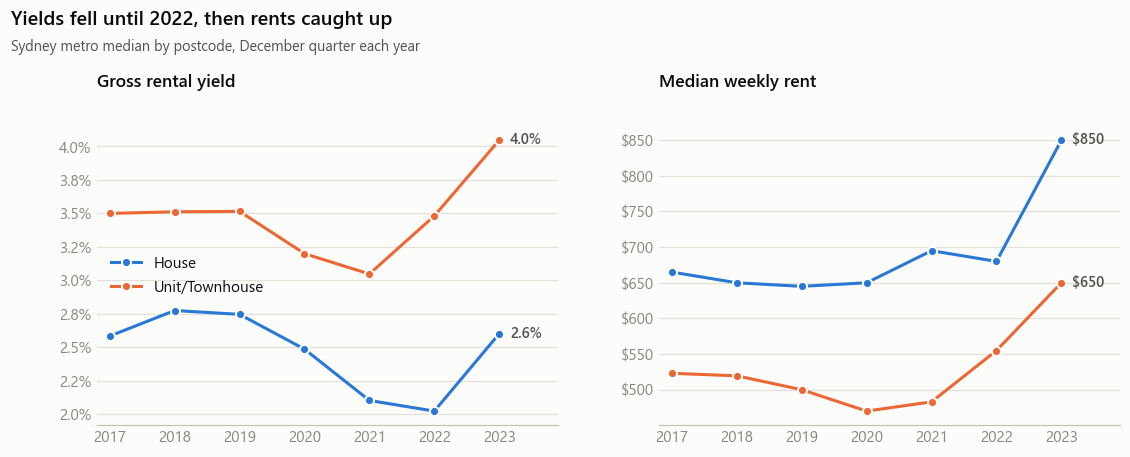

segment,House,Unit/Townhouse
year,,
2017,2.58,3.50
2018,2.77,3.51
2019,2.74,3.51
2020,2.49,3.20
2021,2.10,3.05
2022,2.02,3.48
2023,2.60,4.05


In [2]:
series = yields.groupby(["year", "segment"])["gross_yield_%"].median().unstack()
rent_series = headline.groupby(["year", "segment"]).median_weekly_rent.median().unstack()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"wspace": 0.22})
for seg in SEGMENT_ORDER:
    axes[0].plot(series.index, series[seg], color=SEGMENT_COLORS[seg], marker="o", ms=6,
                 markeredgecolor="white", markeredgewidth=1.3, label=seg)
    axes[0].annotate(f"{series[seg].iloc[-1]:.1f}%", (series.index[-1], series[seg].iloc[-1]),
                     xytext=(7, 0), textcoords="offset points", va="center", fontsize=9.5,
                     fontweight="semibold", color=INK_2)
    axes[1].plot(rent_series.index, rent_series[seg], color=SEGMENT_COLORS[seg], marker="o", ms=6,
                 markeredgecolor="white", markeredgewidth=1.3, label=seg)
    axes[1].annotate(f"${rent_series[seg].iloc[-1]:,.0f}", (rent_series.index[-1], rent_series[seg].iloc[-1]),
                     xytext=(7, 0), textcoords="offset points", va="center", fontsize=9.5,
                     fontweight="semibold", color=INK_2)
axes[0].set_title("Gross rental yield", fontsize=11.5)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}%"))
axes[1].set_title("Median weekly rent", fontsize=11.5)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
for ax in axes:
    ax.set_xlim(series.index.min() - 0.2, series.index.max() + 0.9)
    ax.set_xticks(series.index)
axes[0].legend(loc="center left")
fig_header(fig, "Yields fell until 2022, then rents caught up",
           "Sydney metro median by postcode, December quarter each year", top=0.74)
fig.savefig(FIG / "q9_yield_trend.png")
plt.show()
series.round(2)

### Finding: yields collapsed through the boom, then snapped back as rents surged

| Gross yield (Sydney median postcode) | 2017 | 2021 | 2022 | 2023 |
|---|---:|---:|---:|---:|
| House | 2.58% | 2.10% | **2.02%** | 2.60% |
| Unit/Townhouse | 3.50% | 3.05% | 3.48% | **4.05%** |

- **Prices ran away from rents during the boom.** By 2022 a Sydney house returned barely 2% gross, the weakest in
  the series.
- **2023 reversed it from both directions:** prices fell about 6% while median house rents jumped from $680 to
  **$850 a week** (+25% in a year) and unit rents from $555 to $650.
- **Unit rents fell during COVID** (from $523 a week in 2017 to $470 in 2020) when students and migrants left the
  CBD-fringe apartment market, then recovered sharply.

> **What this means for the fund:** income on a Sydney house has been negligible for most of the decade — the
> investment case was capital growth, financed through a loss on rent after costs. Entering in 2023–24 is a
> materially better income proposition than 2021–22 was, especially for units.

## 2 · The main question: does rental income close the houses-vs-units gap?

Total return = capital growth + gross yield, over the period where rent data exists (2017–2023).
Capital growth uses the like-for-like repeat-sales index from Notebook 02, so it isn't distorted by what sold.

In [3]:
idx = pd.read_csv(EXPORT / "sydney_index_quarterly.csv")
YEARS = 6  # 2017Q4 -> 2023Q4
inflation = (cpi["2023Q4"] / cpi["2017Q4"]) ** (1 / YEARS) - 1
COST_RATIO = 0.75  # assume ownership costs take 25% of gross rent

rows = []
for seg in SEGMENT_ORDER:
    g = idx[idx.segment == seg].set_index("quarter")["repeat_sales_index"]
    growth = (g["2023Q4"] / g["2017Q4"]) ** (1 / YEARS) - 1
    avg_yield = series[seg].mean() / 100
    rows.append({"segment": seg,
                 "capital growth %": growth * 100,
                 "gross yield %": avg_yield * 100,
                 "total return (gross) %": (growth + avg_yield) * 100,
                 "total return after costs %": (growth + avg_yield * COST_RATIO) * 100,
                 "real total return %": (growth + avg_yield * COST_RATIO - inflation) * 100})
total = pd.DataFrame(rows).set_index("segment")
print(f"Inflation over the same period: {inflation * 100:.2f}% a year")
total.round(2)

Inflation over the same period: 3.14% a year


,capital growth %,gross yield %,total return (gross) %,total return after costs %,real total return %
segment,,,,,
House,6.10,2.47,8.58,7.96,4.82
Unit/Townhouse,2.01,3.47,5.48,4.61,1.47


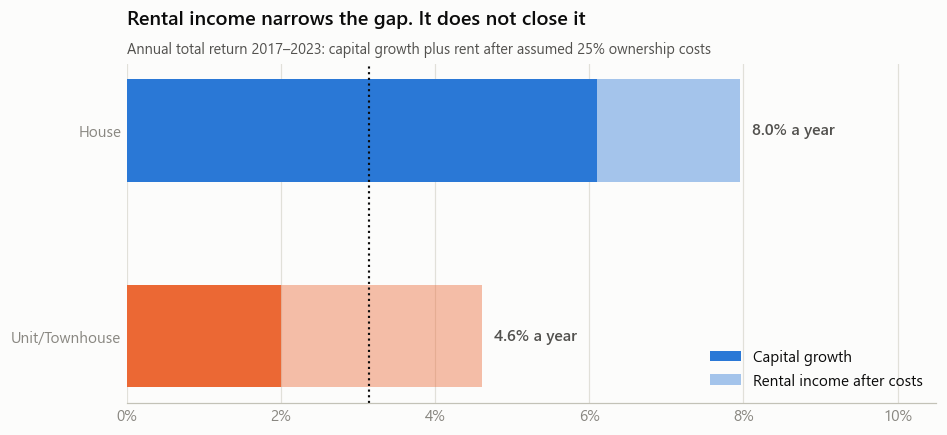

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4))
y = np.arange(len(total))[::-1]
for yi, (seg, r) in zip(y, total.iterrows()):
    ax.barh(yi, r["capital growth %"], height=0.5, color=SEGMENT_COLORS[seg],
            label="Capital growth" if yi == y[0] else None)
    ax.barh(yi, r["gross yield %"] * COST_RATIO, left=r["capital growth %"], height=0.5,
            color=SEGMENT_COLORS[seg], alpha=0.42,
            label="Rental income after costs" if yi == y[0] else None)
    ax.text(r["total return after costs %"] + 0.15, yi, f"{r['total return after costs %']:.1f}% a year",
            va="center", fontsize=10.5, fontweight="semibold", color=INK_2)
ax.axvline(inflation * 100, color="#0b0b0b", lw=1.4, ls=":")
ax.annotate("inflation", (inflation * 100, max(y) + 0.45), fontsize=9, color=INK_2, ha="center")
ax.set_yticks(y, total.index)
ax.set_xlim(0, total["total return after costs %"].max() * 1.32)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_title("Rental income narrows the gap. It does not close it")
subtitle(ax, "Annual total return 2017–2023: capital growth plus rent after assumed 25% ownership costs")
ax.legend(loc="lower right")
fig.savefig(FIG / "q9_total_return.png")
plt.show()

### Finding: rental income narrows the houses-vs-units gap by about a third. It does not close it

Annual total return, 2017–2023 (the window where we have rent data):

| | Capital growth | Gross yield | **Total (after 25% costs)** | Real, after inflation |
|---|---:|---:|---:|---:|
| **House** | 6.10% | 2.47% | **7.96%** | **+4.82%** |
| **Unit/Townhouse** | 2.01% | 3.47% | **4.61%** | **+1.47%** |

- Units earn **1.0 point more income** a year, but houses gained **4.1 points more** in capital growth.
- On capital growth alone houses led by 4.1 points; on total return they still lead by **3.4 points a year**.
  Compounded over six years, that's roughly a **20% difference** in the value of the same money invested.
- **Units barely beat inflation** (1.5% real) once rent is counted at 75% of gross. A fund paying full management
  costs, land tax and periodic vacancy would see less.

> **What this means for the fund:** the open question from notebooks 01–03 is settled. **Rental income does not
> rescue the unit case.** Houses remain the better asset for total return, and the gap is wide enough to survive
> reasonable changes to the cost assumption.
>
> *Caveat:* this compares market medians, not a matched portfolio. Yields vary more by location than by dwelling
> type — see the next section.

## 3 · Where the income is: yield across Sydney

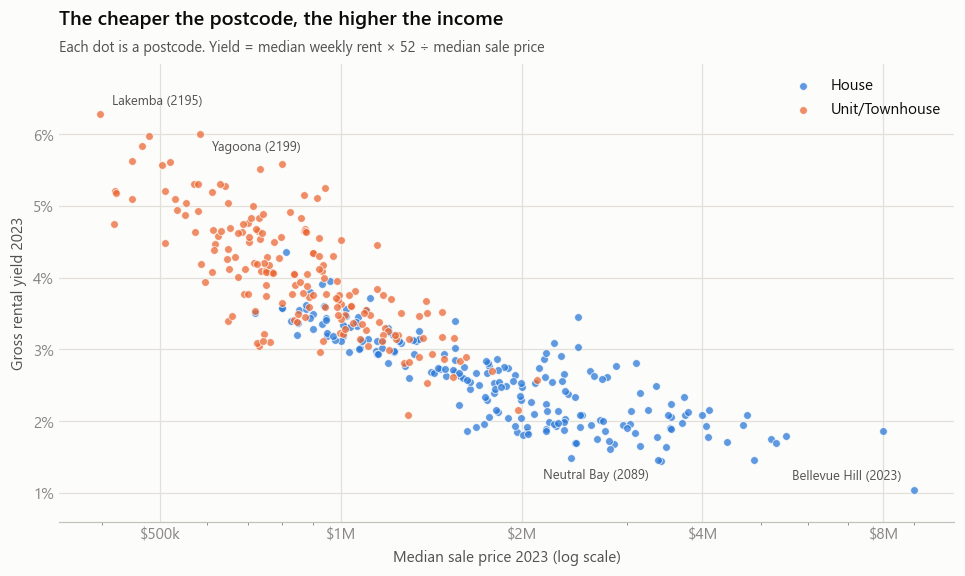

main_suburb,post_code,segment,median_weekly_rent,median_price,gross_yield_%
Lakemba,2195,Unit/Townhouse,480.000000,397700.000000,6.300000
Yagoona,2199,Unit/Townhouse,673.000000,582500.000000,6.000000
Merrylands,2160,Unit/Townhouse,551.000000,480000.000000,6.000000
Punchbowl,2196,Unit/Townhouse,524.000000,466500.000000,5.800000
Guildford,2161,Unit/Townhouse,487.000000,450000.000000,5.600000
Granville,2142,Unit/Townhouse,561.000000,520000.000000,5.600000
Rosebery,2018,Unit/Townhouse,860.000000,800000.000000,5.600000
Bankstown,2200,Unit/Townhouse,541.000000,505000.000000,5.600000


main_suburb,post_code,segment,median_weekly_rent,median_price,gross_yield_%
Bellevue Hill,2023,House,1800.000000,8990000.000000,1.000000
Neutral Bay,2089,House,950.000000,3415000.000000,1.400000
Northbridge,2063,House,1365.000000,4865000.000000,1.500000
Strathfield,2135,House,950.000000,3380000.000000,1.500000
Eastwood,2122,House,690.000000,2420000.000000,1.500000
Burwood,2134,House,870.000000,2810000.000000,1.600000
Gordon,2072,House,1100.000000,3480000.000000,1.600000
St Leonards,2065,House,1000.000000,3150000.000000,1.700000


In [5]:
y2023 = yields[yields.year == 2023].copy()
suburb_pc = sales.groupby("suburb").post_code.agg(lambda c: c.mode().iat[0])
pc_name = (sales[sales.year == 2023].groupby(["post_code", "suburb"]).size().reset_index(name="n")
           .sort_values("n", ascending=False).drop_duplicates("post_code").set_index("post_code")["suburb"])
y2023["main_suburb"] = y2023.post_code.map(pc_name)

fig, ax = plt.subplots(figsize=(10.5, 5.4))
for seg in SEGMENT_ORDER:
    d = y2023[y2023.segment == seg]
    ax.scatter(d.median_price, d["gross_yield_%"], s=26, color=SEGMENT_COLORS[seg], alpha=0.75,
               edgecolor="white", linewidth=0.6, label=seg)
labelled = pd.concat([y2023.nlargest(2, "gross_yield_%"), y2023.nsmallest(2, "gross_yield_%")])
for i, (_, r) in enumerate(labelled.iterrows()):
    right = i >= 2          # cheapest-yield dots sit at the right edge, so label them to the left
    ax.annotate(f"{r.main_suburb} ({int(r.post_code)})", (r.median_price, r["gross_yield_%"]),
                xytext=(-8 if right else 8, -9 if i % 2 else 9), textcoords="offset points",
                fontsize=8.5, color=INK_2, va="center", ha="right" if right else "left")
ax.set_xscale("log")
ax.set_xticks([5e5, 1e6, 2e6, 4e6, 8e6])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1e6:g}M" if v >= 1e6 else f"${v/1e3:.0f}k"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylim(0.6, y2023["gross_yield_%"].max() + 0.7)
ax.set_xlabel("Median sale price 2023 (log scale)")
ax.set_ylabel("Gross rental yield 2023")
ax.grid(axis="x", visible=True)
ax.set_title("The cheaper the postcode, the higher the income")
subtitle(ax, "Each dot is a postcode. Yield = median weekly rent × 52 ÷ median sale price")
ax.legend(loc="upper right")
fig.savefig(FIG / "q9_yield_vs_price.png")
plt.show()

cols = ["main_suburb", "post_code", "segment", "median_weekly_rent", "median_price", "gross_yield_%"]
display(y2023.nlargest(8, "gross_yield_%")[cols].round(1).style.hide(axis="index").set_caption("Highest yield, 2023"))
display(y2023.nsmallest(8, "gross_yield_%")[cols].round(1).style.hide(axis="index").set_caption("Lowest yield, 2023"))

## 4 · Income versus growth: is the trade-off fairly priced?

If the market prices property sensibly, high-yield areas should grow more slowly, and **total** return should end up
similar everywhere. Each postcode's 2023 yield is compared with its like-for-like capital growth (Notebook 02,
nominal, aggregated from suburbs weighted by repeat-sale pairs).

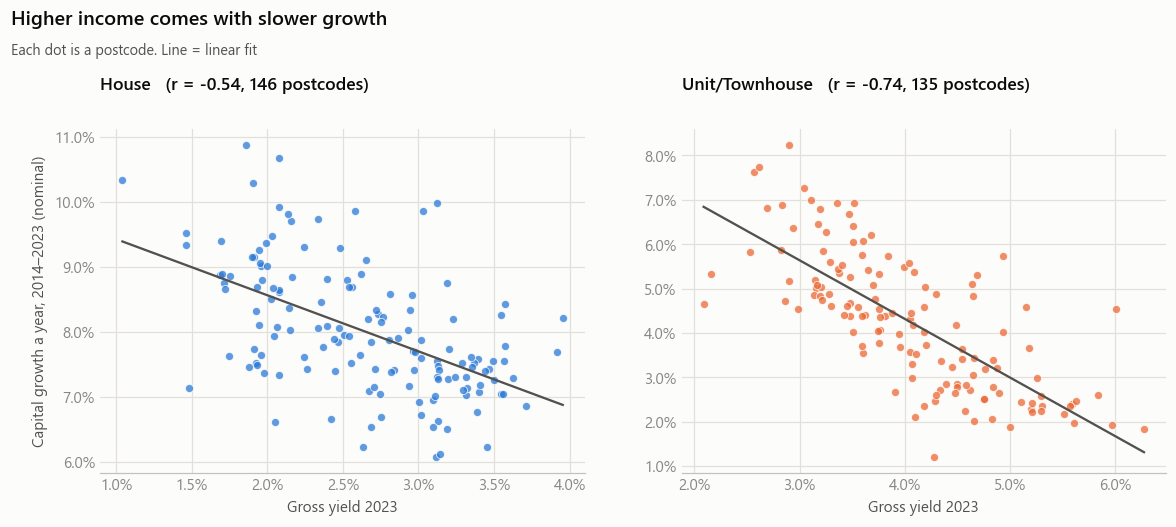

capital growth %  gross yield %  total return %  \
segment        gross_yield_%                                                    
House          Lowest yield               8.64           1.85           10.49   
               2nd                        8.42           2.38           10.80   
               3rd                        7.63           2.91           10.54   
               Highest yield              7.36           3.40           10.76   
Unit/Townhouse Lowest yield               5.79           3.03            8.82   
               2nd                        4.85           3.68            8.54   
               3rd                        3.46           4.32            7.77   
               Highest yield              2.87           5.19            8.06   

                              postcodes  
segment        gross_yield_%             
House          Lowest yield          37  
               2nd                   36  
               3rd                   36  
               Highest yield         37  
Unit/Townhouse Lowest yield          34  
               2nd                   34  
               3rd                   33  
               Highest yield         34

In [6]:
growth = pd.read_csv(EXPORT / "suburb_growth.csv")
growth["post_code"] = growth.suburb.map(suburb_pc)
pc_growth = (growth.groupby(["post_code", "segment"])
             .apply(lambda d: np.average(d["nominal_cagr_%"], weights=d.pairs), include_groups=False)
             .rename("capital_growth_%").reset_index())
tradeoff = y2023.merge(pc_growth, on=["post_code", "segment"])
tradeoff["total_return_%"] = tradeoff["capital_growth_%"] + tradeoff["gross_yield_%"]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"wspace": 0.2})
summaries = {}
for ax, seg in zip(axes, SEGMENT_ORDER):
    d = tradeoff[tradeoff.segment == seg]
    ax.scatter(d["gross_yield_%"], d["capital_growth_%"], s=28, color=SEGMENT_COLORS[seg], alpha=0.75,
               edgecolor="white", linewidth=0.6)
    b = np.polyfit(d["gross_yield_%"], d["capital_growth_%"], 1)
    xs = np.linspace(d["gross_yield_%"].min(), d["gross_yield_%"].max(), 20)
    ax.plot(xs, np.polyval(b, xs), color=INK_2, lw=1.5)
    r = np.corrcoef(d["gross_yield_%"], d["capital_growth_%"])[0, 1]
    ax.set_title(f"{seg}   (r = {r:.2f}, {len(d)} postcodes)", fontsize=11.5)
    ax.set_xlabel("Gross yield 2023")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}%"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}%"))
    ax.grid(axis="x", visible=True)
    q = (d.groupby(pd.qcut(d["gross_yield_%"], 4, labels=["Lowest yield", "2nd", "3rd", "Highest yield"]),
                   observed=True)
         .agg(**{"capital growth %": ("capital_growth_%", "mean"),
                 "gross yield %": ("gross_yield_%", "mean"),
                 "total return %": ("total_return_%", "mean"),
                 "postcodes": ("post_code", "size")}))
    summaries[seg] = q
axes[0].set_ylabel("Capital growth a year, 2014–2023 (nominal)")
fig_header(fig, "Higher income comes with slower growth",
           "Each dot is a postcode. Line = linear fit", top=0.76)
fig.savefig(FIG / "q9_yield_vs_growth.png")
plt.show()
pd.concat(summaries, names=["segment"]).round(2)

### Finding: for houses the market prices the income/growth trade-off almost perfectly. For units it does not

**Houses (r = −0.54): total return is flat across the whole yield range.**

| Yield quartile | Capital growth | Gross yield | **Total return** |
|---|---:|---:|---:|
| Lowest yield (east, north shore) | 8.64% | 1.85% | **10.49%** |
| 2nd | 8.42% | 2.38% | **10.80%** |
| 3rd | 7.63% | 2.91% | **10.54%** |
| Highest yield (west, south-west) | 7.36% | 3.40% | **10.76%** |

Buying a high-yield house market bought income and gave up growth, almost one for one. **Neither strategy beat the
other** — a textbook efficient trade-off, and a strong argument against "chase the yield" or "chase the growth" as
slogans.

**Units (r = −0.74): the trade-off is worse than fair.**

| Yield quartile | Capital growth | Gross yield | **Total return** |
|---|---:|---:|---:|
| Lowest yield | 5.79% | 3.03% | **8.82%** |
| 2nd | 4.85% | 3.68% | **8.54%** |
| 3rd | 3.46% | 4.32% | **7.77%** |
| Highest yield | 2.87% | 5.19% | **8.06%** |

High-yield unit markets (Lakemba, Yagoona, Merrylands at 5.5–6.3% gross) **lost more in growth than they gained in
rent**. These are the same high-supply corridors that Notebook 02 showed losing real value.

> **What this means for the fund:** for houses, choose the yield level that suits the fund's cash-flow needs — the
> market pays you fairly either way. For units, **avoid the high-yield end**: that income has been compensation for
> a weak asset, not a bargain.

## 5 · Rent by bedroom count

In [7]:
beds = rent[(rent.year == 2023) & rent.bedrooms.isin(["1 Bedroom", "2 Bedrooms", "3 Bedrooms", "4 or more Bedrooms"])]
ladder = beds.groupby(["segment", "bedrooms"]).median_weekly_rent.median().unstack()
ladder["3br vs 2br %"] = (ladder["3 Bedrooms"] / ladder["2 Bedrooms"] - 1) * 100
ladder["4br+ vs 3br %"] = (ladder["4 or more Bedrooms"] / ladder["3 Bedrooms"] - 1) * 100
ladder.round(1)

bedrooms,1 Bedroom,2 Bedrooms,3 Bedrooms,4 or more Bedrooms,3br vs 2br %,4br+ vs 3br %
segment,,,,,,
House,475.00,600.00,780.00,"1,000.00",30.00,28.20
Unit/Townhouse,575.00,690.00,"1,000.00",900.00,44.90,-10.00


### Finding: rent rises faster with bedrooms than price does

Median weekly rent, 2023:

| | 1 bed | 2 beds | 3 beds | 4+ beds | 3 vs 2 beds | 4+ vs 3 beds |
|---|---:|---:|---:|---:|---:|---:|
| House | $475 | $600 | $780 | $1,000 | **+30%** | **+28%** |
| Unit/Townhouse | $575 | $690 | $1,000 | $900 | **+45%** | −10% |

Compare this with Q4 (Notebook 03): a 4th bedroom adds only about **5% to a house's price**, but roughly **28% to
its rent**. Bigger houses therefore yield more, which is the opposite of the usual assumption that larger homes are
all growth and no income.

> **What this means for the fund:** **4-bedroom houses look like the income sweet spot** — they cost little more
> than 3-bedroom houses but command far higher rent. For units, stop at 3 bedrooms: 4-bedroom units rent for *less*
> than 3-bedroom ones (a thin, unusual segment).
>
> *Caveat:* rents and prices come from different sources and are medians across postcodes, so treat this as
> indicative rather than a precise yield-by-bedroom figure.

In [8]:
# Exports for the dashboard
out = yields[["year", "post_code", "segment", "median_weekly_rent", "annual_rent", "median_price",
              "sales", "gross_yield_%"]].copy()
out["main_suburb"] = out.post_code.map(pc_name)
out.round(3).to_csv(EXPORT / "yield_by_postcode.csv", index=False)

# Suburb -> postcode lookup so the dashboard can show a postcode yield for every suburb
(suburb_pc.rename("post_code").reset_index().to_csv(EXPORT / "suburb_postcode.csv", index=False))
total.round(3).to_csv(EXPORT / "total_return_by_segment.csv")
print("Exported:", *[p.name for p in sorted(EXPORT.glob("*.csv"))], sep="\n  ")

Exported:
  annual_market.csv
  council_risk_return.csv
  feature_values.csv
  rent_by_postcode.csv
  seasonality.csv
  suburb_annual_medians.csv
  suburb_growth.csv
  suburb_postcode.csv
  suburb_value_gap.csv
  sydney_index_quarterly.csv
  total_return_by_segment.csv
  yield_by_postcode.csv


## Summary for the fund

1. **Rental income does not change the strategy.** Houses returned **8.0% a year** total (growth + net rent) against
   **4.6%** for units, 2017–2023. In real terms, 4.8% vs 1.5%.
2. **Yields are the most attractive they have been all decade**, because 2023 rents rose about 25% while prices fell.
   Units now yield 4.1% gross, houses 2.6%.
3. **For houses, income and growth trade off almost exactly** — total return is about 10.5–10.8% a year in every
   yield quartile. Pick the yield level that matches the fund's cash-flow needs, not a "best" one.
4. **For units, high yield has been a warning sign**, not an opportunity: the highest-yield unit markets gave up more
   growth than they paid in rent.
5. **4-bedroom houses are the income sweet spot:** about 5% more expensive than 3-bedroom houses, but roughly 28%
   more rent.

**Limitations:** gross yields from market medians, not matched properties; costs assumed at 25% of rent; no tax,
leverage, vacancy or transaction costs modelled; rent data starts in 2017, so the 2014–2016 period is growth-only.

**Exports for the dashboard:** `yield_by_postcode.csv`, `rent_by_postcode.csv`, `total_return_by_segment.csv`.